In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


In [2]:

data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:

X = df.drop('target', axis=1)
y = df['target']


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [5]:

model = GaussianNB()

model.fit(X_train, y_train)


GaussianNB()

In [6]:

y_pred = model.predict(X_test)

print("Predicted Values:", y_pred[:10])
print("Actual Values:", y_test.values[:10])


Predicted Values: [0 1 0 1 0 1 1 0 0 0]
Actual Values: [0 1 0 1 0 1 1 0 0 0]


In [7]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")


Accuracy: 0.9385964912280702
Accuracy Percentage: 93.85964912280701 %


In [8]:

cm = confusion_matrix(y_test, y_pred)

print(cm)


[[38  4]
 [ 3 69]]


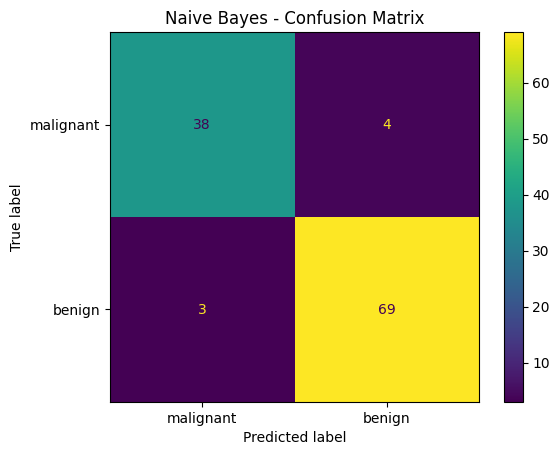

In [9]:

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot()

plt.title("Naive Bayes - Confusion Matrix")
plt.show()


C:\Users\HP\AppData\Roaming\Python\Python39\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


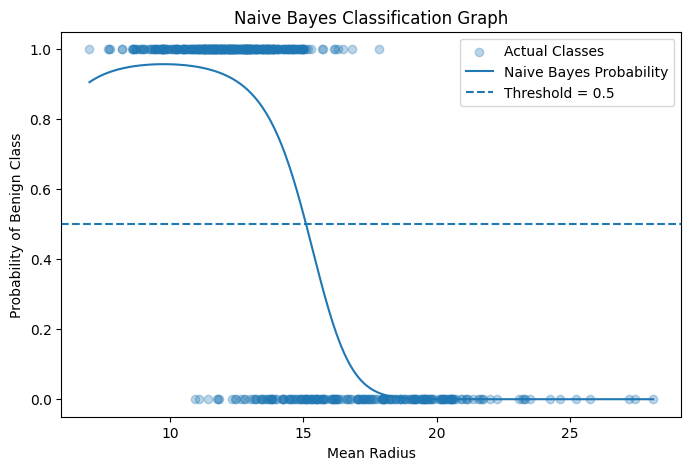

In [10]:

from sklearn.naive_bayes import GaussianNB

X_single = df[['mean radius']]
y_single = df['target']

# Train a separate model using one feature
nb_model = GaussianNB()
nb_model.fit(X_single, y_single)

# Generate values for the graph
x_range = np.linspace(
    X_single['mean radius'].min(),
    X_single['mean radius'].max(),
    300
).reshape(-1, 1)

# Predict probabilities
y_prob = nb_model.predict_proba(x_range)[:, 1]

# Draw graph
plt.figure(figsize=(8, 5))

plt.scatter(
    X_single['mean radius'],
    y_single,
    alpha=0.3,
    label="Actual Classes"
)

plt.plot(
    x_range.ravel(),
    y_prob,
    label="Naive Bayes Probability"
)

plt.axhline(
    y=0.5,
    linestyle='--',
    label="Threshold = 0.5"
)

plt.xlabel("Mean Radius")
plt.ylabel("Probability of Benign Class")
plt.title("Naive Bayes Classification Graph")
plt.legend()
plt.show()
